# Llama 3.2 1B LoRA Fine-Tuning with PEFT on TPU (TorchTPU)

Fine-tune **Llama 3.2 1B Instruct** with **LoRA** (Hugging Face `peft`) on a Cloud TPU using **[TorchTPU](https://github.com/google-pytorch/torch_tpu)**, the native PyTorch backend for TPUs. Standard PyTorch code runs on TPU by using `device="tpu"`.

**Task: text-to-SQL.** Given a table schema and a question, the model must output just the SQL query. The base model tends to add explanations and markdown. After a few hundred LoRA steps it answers with clean SQL, and we measure the gain with exact-match accuracy.

What's inside:

1. Install / check TorchTPU and pick an execution mode (`torch.compile` or the fused eager mode).
2. Load Llama 3.2 1B in bfloat16 on the TPU and wrap it with a LoRA adapter (~11M trainable params, ~0.9%).
3. Build **fixed-shape** batches (padding to a fixed length, loss only on the answer tokens) so XLA compiles the train step **once**.
4. Train with a **`torch.compile`-d forward + loss** (the backward is compiled with it) and AdamW.
5. A compiled, fixed-shape **greedy generator** for evaluation (one compiled graph, no recompiles per token).
6. Compare **base vs LoRA** on held-out questions by toggling the adapter with `disable_adapter()`.
7. Save the adapter, and optionally merge it into the base weights.

**Runtime:** `Runtime → Change runtime type → TPU` (v5e-1 or v6e-1). Without a TPU, the notebook runs a quick CPU smoke test on a 135M model.

In [1]:
# ---- Install (only what's missing) ----
import importlib.util, subprocess, sys

def pip(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

if importlib.util.find_spec("torch_tpu") is None:
    try:
        pip("torch_tpu", "--extra-index-url", "https://download.pytorch.org/whl/cpu")
        print("Installed torch_tpu. If this replaced an already-imported torch, use Runtime -> Restart session, then run on.")
    except Exception as e:
        print("Could not install torch_tpu (fine for a CPU smoke test):", e)
pip("-U", "transformers>=4.51", "peft>=0.15", "datasets")

## 1. Execution mode

TorchTPU has three ways to run your code:

| mode | how | when |
|---|---|---|
| **`torch.compile`** | `torch.compile(fn, dynamic=False)` | best performance. The whole forward + loss (and its backward) becomes one XLA program |
| **Defer-and-fuse eager** | `TORCH_TPU_DEFER_AND_FUSE=1` | no code changes. Fuses runs of eager ops into larger compiled blocks (up to ~50% faster than strict eager) |
| strict eager | default | op-by-op, like CUDA eager |

We **compile the forward + loss** and keep the optimizer step in **defer-and-fuse eager** mode. TorchTPU environment variables are read when the backend initializes, so they must be set **before `import torch`**.

In [2]:
import os
USE_TORCH_COMPILE = True                      # False -> pure eager (defer-and-fuse)
os.environ.setdefault("TORCH_TPU_DEFER_AND_FUSE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import importlib.util, math, re, time, random, gc, warnings
import torch
warnings.filterwarnings("ignore", message="The .grad attribute of a Tensor that is not a leaf")
import torch.nn.functional as F

ON_TPU = importlib.util.find_spec("torch_tpu") is not None and torch.accelerator.is_available() \
         and torch.accelerator.current_accelerator().type == "tpu"
device = torch.device("tpu") if ON_TPU else torch.device("cpu")

print("torch", torch.__version__, "| device:", device)
if ON_TPU:
    # get_device_properties() is experimental and its fields differ between TorchTPU builds.
    props = torch.tpu.get_device_properties()
    hbm = getattr(props, "hbm_bytes_per_device", None) or getattr(props, "hbm_bytes_per_chip", None) \
          or getattr(props, "total_memory", None)
    print(f"TPU: {getattr(props, 'name', props)} | devices visible: {torch.accelerator.device_count()}"
          + (f" | HBM: {hbm / 2**30:.1f} GiB" if hbm else ""))
else:
    print("No TPU found -> CPU smoke-test mode (small model, few steps).")

torch 2.14.1+cpu | device: tpu
TPU: TPU v5e | devices visible: 1 | HBM: 16.0 GiB


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
/tmp/ipykernel_1176/2609378703.py:18: UserWarning: <TorchTpu/ApiStage/ExperimentalApi/> get_device_properties is experimental and subject to change: get_device_properties() is experimental and subject to change without notice.
  props = torch.tpu.get_device_properties()


## 2. Configuration

`meta-llama/Llama-3.2-1B-Instruct` is **gated**. Accept the license on its Hugging Face page and add your token as a Colab secret named `HF_TOKEN` (🔑 icon in the left sidebar). If no token is found, the notebook falls back to `unsloth/Llama-3.2-1B-Instruct`, an ungated copy of the same weights.

In [3]:
def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")

HF_TOKEN = get_hf_token()
if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN, add_to_git_credential=False)

if ON_TPU:
    MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct" if HF_TOKEN else "unsloth/Llama-3.2-1B-Instruct"
    MAX_LEN, BATCH_SIZE, MAX_STEPS, EVAL_EXAMPLES = 256, 8, 400, 200
else:   # CPU smoke test
    MODEL_ID = os.environ.get("SMOKE_MODEL_ID", "HuggingFaceTB/SmolLM2-135M-Instruct")
    MAX_LEN, BATCH_SIZE, MAX_STEPS, EVAL_EXAMPLES = 256, 4, 30, 16

ANSWER_LEN = 64                    # max supervised (answer) tokens per example; covers ~99% of this dataset
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LR, WARMUP_STEPS, WEIGHT_DECAY, GRAD_CLIP = 2e-4, 20, 0.0, 1.0
MAX_NEW_TOKENS = 96
GRADIENT_CHECKPOINTING = False     # set True if you still hit HBM OOM (e.g. larger BATCH_SIZE / MAX_LEN)
SEED = 0
OUTPUT_DIR = "llama32-1b-sql-lora"

random.seed(SEED); torch.manual_seed(SEED)
print("model:", MODEL_ID)

model: unsloth/Llama-3.2-1B-Instruct


## 3. Load the model and add LoRA

The base weights stay frozen in **bfloat16**. LoRA adds low-rank `A·B` updates to every attention and MLP projection (`q, k, v, o, gate, up, down`). PEFT keeps the adapter weights in float32 by default, which is good for optimizer stability.

In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
PAD_ID = tokenizer.pad_token_id

t0 = time.time()
base_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.bfloat16, attn_implementation="sdpa")
base_model.config.use_cache = False
base_model.to(device)

lora_cfg = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(base_model, lora_cfg)
if GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
model.to(device)
print(f"loaded in {time.time() - t0:.1f}s")
model.print_trainable_parameters()

N_PARAMS = sum(p.numel() for p in model.parameters())
trainable = [p for p in model.parameters() if p.requires_grad]
print("adapter dtype:", trainable[0].dtype, "| device:", trainable[0].device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/894 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

loaded in 30.4s
trainable params: 11,272,192 || all params: 1,509,754,880 || trainable%: 0.7466
adapter dtype: torch.float32 | device: tpu:0


## 4. Data: text-to-SQL with fixed shapes

Dataset: [`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context) (78k `question`, `CREATE TABLE` context, and SQL `answer` triples).

Each example is formatted with the model's chat template, and:
* **labels are `-100` on the prompt**, so the loss covers only the SQL answer and the end-of-turn token,
* sequences are **right-padded to a fixed `MAX_LEN`**, and examples that don't fit are dropped,
* for each row we also record the (at most `ANSWER_LEN`) **positions that predict answer tokens**. The loss computes vocabulary logits **only there**, instead of at every position.

**Why that matters for memory:** Llama 3.2 has a 128k vocabulary. Logits for every position of a `[8, 256]` batch take ~1 GB in bf16 and ~2 GB in float32, before counting their gradients. Only ~30 of the 256 positions per row are answer tokens, so computing logits on `[8, 64]` positions cuts this 4x.

Because attention is causal, padding at the *end* never affects real tokens. So we don't even pass an `attention_mask`, and every batch has the same shape `[BATCH_SIZE, MAX_LEN]`. XLA then compiles the training step **once**.

In [5]:
from datasets import load_dataset

SYSTEM = "You are a text-to-SQL assistant. Reply with only the SQL query, no explanation."

def messages_for(ex, with_answer=True):
    user = f"Schema:\n{ex['context']}\n\nQuestion: {ex['question']}"
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]
    if with_answer:
        msgs.append({"role": "assistant", "content": ex["answer"]})
    return msgs

def encode_prompt(ex):
    text = tokenizer.apply_chat_template(messages_for(ex, False), tokenize=False, add_generation_prompt=True)
    return tokenizer(text, add_special_tokens=False)["input_ids"]

def encode_train(ex):
    prompt_ids = encode_prompt(ex)
    full_text = tokenizer.apply_chat_template(messages_for(ex, True), tokenize=False)
    full_ids = tokenizer(full_text, add_special_tokens=False)["input_ids"]
    assert full_ids[:len(prompt_ids)] == prompt_ids, "chat template prompt is not a prefix of the full text"
    labels = [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]
    return {"input_ids": full_ids, "labels": labels, "length": len(full_ids),
            "answer_start": len(prompt_ids), "answer_len": len(full_ids) - len(prompt_ids)}

raw = load_dataset("b-mc2/sql-create-context", split="train").shuffle(seed=SEED)
eval_raw = raw.select(range(EVAL_EXAMPLES))
n_train = min(len(raw) - EVAL_EXAMPLES, MAX_STEPS * BATCH_SIZE + 2000)
train_ds = raw.select(range(EVAL_EXAMPLES, EVAL_EXAMPLES + n_train)).map(
    encode_train, remove_columns=raw.column_names, num_proc=1)
train_ds = train_ds.filter(lambda ex: ex["length"] <= MAX_LEN and ex["answer_len"] <= ANSWER_LEN)
print(f"train examples: {len(train_ds)} | eval examples: {len(eval_raw)}")
print(f"mean length: {sum(train_ds['length']) / len(train_ds):.0f} tokens (padded to {MAX_LEN})")

def pad_batch(examples):
    # ids/labels: [B, MAX_LEN]. pos/tgt: [B, ANSWER_LEN] = positions whose hidden state predicts each
    # answer token, and those tokens (-100 = padding). All shapes are fixed.
    B = len(examples)
    ids = torch.full((B, MAX_LEN), PAD_ID, dtype=torch.long)
    labels = torch.full((B, MAX_LEN), -100, dtype=torch.long)
    pos = torch.zeros((B, ANSWER_LEN), dtype=torch.long)
    tgt = torch.full((B, ANSWER_LEN), -100, dtype=torch.long)
    for i, ex in enumerate(examples):
        n, a0, na = len(ex["input_ids"]), ex["answer_start"], ex["answer_len"]
        ids[i, :n] = torch.tensor(ex["input_ids"])
        labels[i, :n] = torch.tensor(ex["labels"])
        pos[i, :na] = torch.arange(a0 - 1, a0 - 1 + na)      # token t is predicted by position t-1
        tgt[i, :na] = torch.tensor(ex["input_ids"][a0:a0 + na])
    return ids, labels, pos, tgt

def batches(ds, batch_size, seed):
    order = list(range(len(ds)))
    epoch = 0
    while True:
        random.Random(seed + epoch).shuffle(order)
        for i in range(0, len(order) - batch_size + 1, batch_size):      # drop_last -> fixed shapes
            yield pad_batch([ds[j] for j in order[i:i + batch_size]])
        epoch += 1

ids, labels, _, _ = next(batches(train_ds, 1, SEED))
print("\n--- example (loss only on the part after the prompt) ---")
print(tokenizer.decode(ids[0][ids[0] != PAD_ID]))
print("--- supervised part ---")
print(tokenizer.decode(labels[0][labels[0] != -100]))

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Map (num_proc=1):   0%|          | 0/5200 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5200 [00:00<?, ? examples/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


train examples: 5182 | eval examples: 200
mean length: 113 tokens (padded to 256)

--- example (loss only on the part after the prompt) ---
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 07 Nov 2026

You are a text-to-SQL assistant. Reply with only the SQL query, no explanation.<|eot_id|><|start_header_id|>user<|end_header_id|>

Schema:
CREATE TABLE table_15781170_3 (root_of_all_evil VARCHAR, poll_winner VARCHAR)

Question: When bloggers was the poll winner, who was the root of all evil?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

SELECT root_of_all_evil FROM table_15781170_3 WHERE poll_winner = "Bloggers"<|eot_id|>
--- supervised part ---
SELECT root_of_all_evil FROM table_15781170_3 WHERE poll_winner = "Bloggers"<|eot_id|>


## 5. Compiled greedy generation for evaluation

Hugging Face `generate()` with a growing KV cache changes tensor shapes at every token, and on TPU each new shape means a recompile. For evaluation we use a **fixed-shape** generator instead:

* a `[B, PROMPT_LEN + MAX_NEW_TOKENS]` token buffer,
* each step runs the full forward on that buffer, takes the hidden state at each row's current last position, and applies the LM head to just that position,
* the forward is `torch.compile`-d once and reused for every step and every batch.

There's no KV cache, so it does extra compute, but at these sizes the TPU handles it quickly and it never recompiles. `with model.disable_adapter():` gives the base model's answers for comparison, without loading a second copy.

In [6]:
inner = model.get_base_model()            # LlamaForCausalLM with LoRA layers injected in place

def next_token_logits(ids, last_pos):
    h = inner.model(input_ids=ids).last_hidden_state                       # [B, T, D]
    h_last = h.gather(1, last_pos[:, None, None].expand(-1, 1, h.shape[-1]))[:, 0]
    return inner.lm_head(h_last).float()                                   # [B, V]

gen_forward = torch.compile(next_token_logits, dynamic=False) if USE_TORCH_COMPILE else next_token_logits

STOP_IDS = {i for i in [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|eot_id|>"),
                        tokenizer.convert_tokens_to_ids("<|im_end|>")] if isinstance(i, int) and i >= 0}

@torch.no_grad()
def generate_sql(examples, batch_size=None, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    batch_size = batch_size or BATCH_SIZE
    T = MAX_LEN + max_new_tokens
    outputs = []
    for s in range(0, len(examples), batch_size):
        chunk = examples[s:s + batch_size]
        prompts = [encode_prompt(ex)[-MAX_LEN:] for ex in chunk]
        prompts += [prompts[-1]] * (batch_size - len(prompts))             # pad batch -> fixed shape
        ids = torch.full((batch_size, T), PAD_ID, dtype=torch.long)
        for i, p in enumerate(prompts):
            ids[i, :len(p)] = torch.tensor(p)
        lengths = torch.tensor([len(p) for p in prompts])
        ids, lengths_dev = ids.to(device), lengths.to(device)
        new_tokens = []
        for _ in range(max_new_tokens):
            nxt = gen_forward(ids, lengths_dev - 1).argmax(-1)                  # [B]
            ids = ids.scatter(1, lengths_dev[:, None], nxt[:, None])
            lengths_dev = lengths_dev + 1
            new_tokens.append(nxt)
        new_tokens = torch.stack(new_tokens, 1).cpu().tolist()                 # one host transfer per batch
        for row in new_tokens[:len(chunk)]:
            cut = next((k for k, t in enumerate(row) if t in STOP_IDS), len(row))
            outputs.append(tokenizer.decode(row[:cut], skip_special_tokens=True).strip())
    model.train()
    return outputs

def normalize_sql(s):
    s = re.sub(r"^```(?:sql)?|```$", "", s.strip(), flags=re.I).strip()
    return re.sub(r"\s+", " ", s).strip().rstrip(";").strip().lower()

def exact_match(preds, refs):
    return sum(normalize_sql(p) == normalize_sql(r) for p, r in zip(preds, refs)) / len(refs)

eval_examples = [eval_raw[i] for i in range(len(eval_raw))]
eval_refs = [ex["answer"] for ex in eval_examples]

t0 = time.time()
with model.disable_adapter():
    base_preds = generate_sql(eval_examples)
base_em = exact_match(base_preds, eval_refs)
print(f"BASE model exact match: {100 * base_em:.1f}%  ({time.time() - t0:.1f}s incl. compilation)\n")
for ex, p in list(zip(eval_examples, base_preds))[:3]:
    print("Q:   ", ex["question"]); print("REF: ", ex["answer"]); print("BASE:", p[:300], "\n")

BASE model exact match: 12.5%  (116.6s incl. compilation)

Q:    What is the lowest unlock order for the athens circuit?
REF:  SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
BASE: SELECT MIN unlock_order FROM table_24463470_1 WHERE circuit = 'athens' 

Q:    What is the highest pick number of a defensive back with less than 136 overall points?
REF:  SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
BASE: SELECT MAX pick__number FROM table_name_99 WHERE overall < '136' AND position = 'defensive back' 

Q:    Which engine has a year larger than 1956?
REF:  SELECT engine FROM table_name_74 WHERE year > 1956
BASE: SELECT engine FROM table_name_74 WHERE year > 1956 



## 6. Training loop

* `compute_loss` runs the transformer, gathers the hidden states at the answer positions, applies the LM head **only there**, and computes cross-entropy (ignoring `-100`). It is wrapped in `torch.compile(dynamic=False)`. AOTAutograd compiles the matching **backward** graph, so `loss.backward()` also runs as one XLA program.
* `torch.optim.AdamW` updates only the LoRA parameters, with warmup + cosine LR.
* We avoid host syncs inside the loop: the loss is only copied to the CPU (`.item()`) every `LOG_EVERY` steps.

The first step compiles (often a minute or more for a 1B model). Later steps reuse the cached executable.

In [7]:
from transformers import get_cosine_schedule_with_warmup

def compute_loss(input_ids, pos, tgt):
    h = inner.model(input_ids=input_ids).last_hidden_state                     # [B, T, D]
    h_ans = h.gather(1, pos[:, :, None].expand(-1, -1, h.shape[-1]))           # [B, A, D]
    logits = inner.lm_head(h_ans).float()                                      # [B, A, V] (not [B, T, V])
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), ignore_index=-100)

loss_fn = torch.compile(compute_loss, dynamic=False) if USE_TORCH_COMPILE else compute_loss

optimizer = torch.optim.AdamW(trainable, lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999))
scheduler = get_cosine_schedule_with_warmup(optimizer, WARMUP_STEPS, MAX_STEPS)

def train_step(input_ids, pos, tgt):
    loss = loss_fn(input_ids, pos, tgt)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(trainable, GRAD_CLIP)
    optimizer.step()
    scheduler.step()
    optimizer.zero_grad(set_to_none=True)
    return loss.detach()

LOG_EVERY = 25 if ON_TPU else 5
model.train()
data_iter = batches(train_ds, BATCH_SIZE, SEED)
history, real_tokens = [], 0

# First step: compile (with a fallback to eager if compilation fails for any reason).
def to_dev(batch):
    ids, _, pos, tgt = batch
    return ids.to(device), pos.to(device), tgt.to(device)

batch = next(data_iter)
t0 = time.time()
try:
    loss = train_step(*to_dev(batch)); loss_val = loss.item()
except Exception as e:
    print("torch.compile failed, falling back to eager:", repr(e)[:300])
    loss = None; optimizer.zero_grad(set_to_none=True)
    gc.collect(); torch.accelerator.empty_cache()                # release the failed attempt's buffers
    loss_fn = compute_loss
    loss = train_step(*to_dev(batch)); loss_val = loss.item()
print(f"step    1 | loss {loss_val:.4f} | first step (compile) {time.time() - t0:.1f}s")
history.append((1, loss_val))

t_start, pending = time.time(), []
for step in range(2, MAX_STEPS + 1):
    batch = next(data_iter)
    real_tokens += int((batch[0] != PAD_ID).sum())
    pending.append(train_step(*to_dev(batch)))
    if step % LOG_EVERY == 0 or step == MAX_STEPS:
        losses = torch.stack(pending).float().cpu()            # single sync for the whole window
        pending = []
        elapsed = time.time() - t_start
        history.append((step, float(losses.mean())))
        print(f"step {step:4d} | loss {losses.mean():.4f} | lr {scheduler.get_last_lr()[0]:.2e} "
              f"| {(step - 1) * BATCH_SIZE * MAX_LEN / elapsed:,.0f} tok/s (padded) "
              f"| {real_tokens / elapsed:,.0f} tok/s (real)")

train_time = time.time() - t_start
padded_tok_s = (MAX_STEPS - 1) * BATCH_SIZE * MAX_LEN / train_time
# LoRA FLOPs/token ~ 2N (forward) + 2N (backward wrt activations); weight grads only for tiny adapters.
tflops = 4 * N_PARAMS * padded_tok_s / 1e12
msg = f"\n{MAX_STEPS - 1} steps in {train_time:.1f}s | ~{tflops:.1f} TFLOP/s model FLOPs"
if ON_TPU:
    p = torch.tpu.get_device_properties()
    peak = getattr(p, "bf16_flops_per_device", None)
    if peak is None and getattr(p, "bf16_flops_per_chip", None):
        peak = p.bf16_flops_per_chip / max(getattr(p, "devices_per_chip", 1) or 1, 1)
    if peak:
        msg += f" | MFU ~{100 * tflops * 1e12 / peak:.0f}%"
print(msg)
if ON_TPU:
    try:
        print(f"peak TPU memory: {torch.accelerator.max_memory_allocated() / 2**30:.2f} GiB")
    except Exception:
        pass

step    1 | loss 0.1661 | first step (compile) 36.8s
step   25 | loss 0.1553 | lr 2.00e-04 | 8,944 tok/s (padded) | 3,937 tok/s (real)
step   50 | loss 0.1138 | lr 1.97e-04 | 11,579 tok/s (padded) | 5,092 tok/s (real)
step   75 | loss 0.0868 | lr 1.90e-04 | 12,837 tok/s (padded) | 5,665 tok/s (real)
step  100 | loss 0.0822 | lr 1.79e-04 | 13,567 tok/s (padded) | 5,987 tok/s (real)
step  125 | loss 0.0693 | lr 1.65e-04 | 14,026 tok/s (padded) | 6,202 tok/s (real)
step  150 | loss 0.0607 | lr 1.48e-04 | 14,352 tok/s (padded) | 6,322 tok/s (real)
step  175 | loss 0.0815 | lr 1.29e-04 | 14,589 tok/s (padded) | 6,436 tok/s (real)
step  200 | loss 0.0682 | lr 1.08e-04 | 14,773 tok/s (padded) | 6,511 tok/s (real)
step  225 | loss 0.0810 | lr 8.76e-05 | 14,929 tok/s (padded) | 6,579 tok/s (real)
step  250 | loss 0.0574 | lr 6.75e-05 | 15,048 tok/s (padded) | 6,624 tok/s (real)
step  275 | loss 0.0547 | lr 4.88e-05 | 15,145 tok/s (padded) | 6,681 tok/s (real)
step  300 | loss 0.0716 | lr 3.23e-

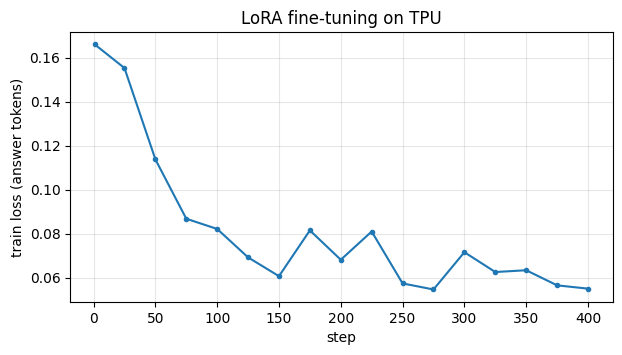

In [8]:
import matplotlib.pyplot as plt
s, l = zip(*history)
plt.figure(figsize=(7, 3.5)); plt.plot(s, l, marker="o", ms=3)
plt.xlabel("step"); plt.ylabel("train loss (answer tokens)"); plt.title("LoRA fine-tuning on TPU")
plt.grid(alpha=0.3); plt.show()

## 7. Evaluate: base vs LoRA

Same held-out questions, same compiled generator. Only the adapter is switched on.

In [9]:
t0 = time.time()
lora_preds = generate_sql(eval_examples)
lora_em = exact_match(lora_preds, eval_refs)
print(f"Exact match on {len(eval_refs)} held-out questions:")
print(f"  base model : {100 * base_em:5.1f}%")
print(f"  + LoRA     : {100 * lora_em:5.1f}%   ({time.time() - t0:.1f}s)\n")
for ex, b, p in list(zip(eval_examples, base_preds, lora_preds))[:5]:
    print("Q:    ", ex["question"])
    print("REF:  ", ex["answer"])
    print("BASE: ", b[:200].replace("\n", " "))
    print("LoRA: ", p, "\n")

Exact match on 200 held-out questions:
  base model :  12.5%
  + LoRA     :  79.0%   (130.7s)

Q:     What is the lowest unlock order for the athens circuit?
REF:   SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
BASE:  SELECT MIN unlock_order FROM table_24463470_1 WHERE circuit = 'athens'
LoRA:  SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens" 

Q:     What is the highest pick number of a defensive back with less than 136 overall points?
REF:   SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
BASE:  SELECT MAX pick__number FROM table_name_99 WHERE overall < '136' AND position = 'defensive back'
LoRA:  SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back" 

Q:     Which engine has a year larger than 1956?
REF:   SELECT engine FROM table_name_74 WHERE year > 1956
BASE:  SELECT engine FROM table_name_74 WHERE year > 1956
LoRA:  SELECT engine FROM table_n

## 8. Save the adapter (and optionally merge it)

The adapter is only a few tens of MB. We copy just the LoRA tensors to the CPU before saving, so the 1B base weights never leave the TPU. To deploy without PEFT, `merge_and_unload()` folds `B·A` into the base weights.

In [10]:
lora_state = {k: v.detach().to("cpu") for k, v in model.state_dict().items() if "lora_" in k}
model.save_pretrained(OUTPUT_DIR, state_dict=lora_state)
tokenizer.save_pretrained(OUTPUT_DIR)
size_mb = sum(os.path.getsize(os.path.join(OUTPUT_DIR, f)) for f in os.listdir(OUTPUT_DIR)) / 2**20
print(f"saved adapter to ./{OUTPUT_DIR} ({size_mb:.1f} MB):", sorted(os.listdir(OUTPUT_DIR)))

MERGE_AND_SAVE = False          # True -> write a standalone merged model (~2.5 GB)
PUSH_TO_HUB = None              # e.g. "your-username/llama32-1b-sql-lora"

if MERGE_AND_SAVE:
    merged = model.merge_and_unload().to("cpu")
    merged.save_pretrained(OUTPUT_DIR + "-merged"); tokenizer.save_pretrained(OUTPUT_DIR + "-merged")
    print("merged model saved to", OUTPUT_DIR + "-merged")
if PUSH_TO_HUB:
    model.push_to_hub(PUSH_TO_HUB, state_dict=lora_state); tokenizer.push_to_hub(PUSH_TO_HUB)

saved adapter to ./llama32-1b-sql-lora (59.5 MB): ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']
